Comparing the number of male and female homicides happened in US per 100,000 population.

#Analysis is done using cleaned data 

['state_fips', 'state_abb', 'year', 'pop_total', 'pop_female', 'pop_male', 'pop_female_15plus']
      Female victims  Male victims  Female per 100k  Male per 100k
year                                                              
1976            4114         13484             3.68          12.74
1977            4489         14270             3.98          13.35
1978            4506         14995             3.95          13.89
1979            4906         16778             4.25          15.37
1980            4983         17784             4.27          16.11
1981            4550         16364             3.86          14.68
1982            4736         15537             3.98          13.80
1983            4615         15019             3.84          13.22
1984            4461         13595             3.68          11.86
1985            4590         13775             3.76          11.90
1986            4862         15234             3.94          13.04
1987            4800         1396

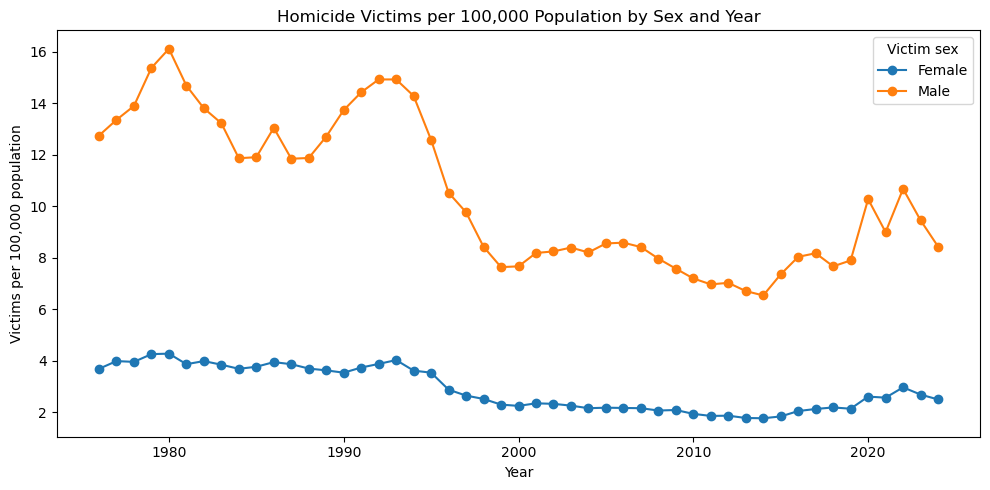

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

FILE = "shr_victims_clean.csv"
POP_FILE = "population_state_year.csv"
YEAR_COL = "year"
SEX_COL = "victim_sex"
STATE_COL = "state"

POP_STATE_COL = "state_abb"
POP_YEAR_COL = "year"
POP_FEMALE_COL = "pop_female"
POP_MALE_COL = "pop_male"
PER = 100_000

STATE_ABB = {
    "ALABAMA": "AL", "ALASKA": "AK", "ARIZONA": "AZ", "ARKANSAS": "AR", "CALIFORNIA": "CA",
    "COLORADO": "CO", "CONNECTICUT": "CT", "DELAWARE": "DE", "DISTRICT OF COLUMBIA": "DC",
    "FLORIDA": "FL", "GEORGIA": "GA", "HAWAII": "HI", "IDAHO": "ID", "ILLINOIS": "IL",
    "INDIANA": "IN", "IOWA": "IA", "KANSAS": "KS", "KENTUCKY": "KY", "LOUISIANA": "LA",
    "MAINE": "ME", "MARYLAND": "MD", "MASSACHUSETTS": "MA", "MICHIGAN": "MI", "MINNESOTA": "MN",
    "MISSISSIPPI": "MS", "MISSOURI": "MO", "MONTANA": "MT", "NEBRASKA": "NE", "NEVADA": "NV",
    "NEW HAMPSHIRE": "NH", "NEW JERSEY": "NJ", "NEW MEXICO": "NM", "NEW YORK": "NY",
    "NORTH CAROLINA": "NC", "NORTH DAKOTA": "ND", "OHIO": "OH", "OKLAHOMA": "OK", "OREGON": "OR",
    "PENNSYLVANIA": "PA", "RHODE ISLAND": "RI", "SOUTH CAROLINA": "SC", "SOUTH DAKOTA": "SD",
    "TENNESSEE": "TN", "TEXAS": "TX", "UTAH": "UT", "VERMONT": "VT", "VIRGINIA": "VA",
    "WASHINGTON": "WA", "WEST VIRGINIA": "WV", "WISCONSIN": "WI", "WYOMING": "WY",
}

sex_map = {
    "male": "Male", "m": "Male", "man": "Male",
    "female": "Female", "f": "Female", "woman": "Female",
}



df = pd.read_csv(FILE, low_memory=False)
print(pd.read_csv("population_state_year.csv", nrows=5).columns.tolist())
df["sex_group"] = df[SEX_COL].astype("string").str.strip().str.lower().map(sex_map)
df[YEAR_COL] = pd.to_numeric(df[YEAR_COL], errors="coerce")
df[STATE_COL] = df[STATE_COL].astype("string").str.strip().str.upper().map(STATE_ABB)
df = df.dropna(subset=[YEAR_COL, "sex_group", STATE_COL])
df[YEAR_COL] = df[YEAR_COL].astype(int)

pop = pd.read_csv(POP_FILE, low_memory=False)
pop = pop.rename(columns={POP_STATE_COL: STATE_COL, POP_YEAR_COL: YEAR_COL})
pop[STATE_COL] = pop[STATE_COL].astype("string").str.strip().str.upper()
pop[YEAR_COL] = pd.to_numeric(pop[YEAR_COL], errors="coerce")
pop = pop.dropna(subset=[YEAR_COL])
pop[YEAR_COL] = pop[YEAR_COL].astype(int)

missing = sorted(set(df[STATE_COL].dropna()) - set(pop[STATE_COL].dropna()))
if missing:
    print("Victim states not in population file (excluded):", missing)
df = df[df[STATE_COL].isin(pop[STATE_COL])]

pop_long = pop.melt(
    id_vars=[STATE_COL, YEAR_COL],
    value_vars=[POP_FEMALE_COL, POP_MALE_COL],
    var_name="sex_group",
    value_name="population",
)
pop_long["sex_group"] = pop_long["sex_group"].map({POP_FEMALE_COL: "Female", POP_MALE_COL: "Male"})
pop_long["population"] = pd.to_numeric(pop_long["population"], errors="coerce")

victims = (
    df.groupby([YEAR_COL, "sex_group"]).size()
      .unstack(fill_value=0)
      .reindex(columns=["Female", "Male"], fill_value=0)
)
popn = (
    pop_long.groupby([YEAR_COL, "sex_group"])["population"].sum()
      .unstack()
      .reindex(columns=["Female", "Male"])
)

years = victims.index.intersection(popn.index).sort_values()
victims = victims.loc[years]
popn = popn.loc[years]
rates = (victims / popn * PER).round(2)

summary = pd.DataFrame({
    "Female victims": victims["Female"],
    "Male victims": victims["Male"],
    "Female per 100k": rates["Female"],
    "Male per 100k": rates["Male"],
})
print(summary)

ax = rates.plot(kind="line", marker="o", figsize=(10, 5))
ax.set(
    title="Homicide Victims per 100,000 Population by Sex and Year",
    xlabel="Year",
    ylabel="Victims per 100,000 population",
)
ax.legend(title="Victim sex")
plt.tight_layout()
plt.show()

Femicide : As per UN, femicide (also called feminicide) is the intentional killing of women or girls because of their gender. Unlike the general term homicide, femicide highlights gender-based motivations, unequal power dynamics, and systemic discrimination.
Comparing gender based violence by their intimate partners.

Matched relationship labels:
relation_to_offender_1
victim was wife                  28956
victim was girlfriend            22853
victim was husband               12330
victim was boyfriend             10555
victim was common-law wife        3382
victim was common-law husband     2746
victim was ex-wife                2449
victim was ex-husband              960
Name: count, dtype: int64
sex_group  Female victims  Male victims  Female per 100k  Male per 100k
year                                                                   
1976                 1401          1156            1.254          1.092
1977                 1333          1165            1.181          1.090
1978                 1412          1115            1.237          1.033
1979                 1449          1188            1.255          1.089
1980                 1455          1112            1.245          1.007
1981                 1374          1095            1.165          0.982
1982                 1344         

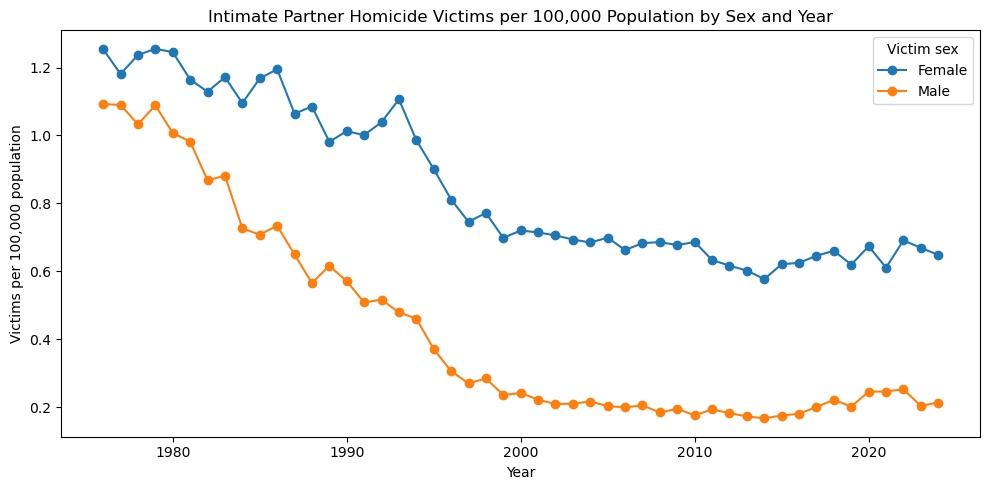

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

FILE = "shr_victims_clean.csv"
POP_FILE = "population_state_year.csv"
SEX_COL = "victim_sex"
STATE_COL = "state"
YEAR_COL = "year"
REL_COL = "relation_to_offender_1"
INTIMATE_PATTERN = r"intimate|spouse|husband|wife|boyfriend|girlfriend"
PER = 100_000

sex_map = {
    "male": "Male", "m": "Male", "man": "Male",
    "female": "Female", "f": "Female", "woman": "Female",
}

df = pd.read_csv(FILE, low_memory=False)
df["sex_group"] = df[SEX_COL].astype("string").str.strip().str.lower().map(sex_map)
df[YEAR_COL] = pd.to_numeric(df[YEAR_COL], errors="coerce")
df[STATE_COL] = df[STATE_COL].astype("string").str.strip().str.upper().map(STATE_ABB)

rel = df[REL_COL].fillna("Unknown").astype(str).str.strip()
is_intimate = rel.str.contains(INTIMATE_PATTERN, case=False, regex=True)
print("Matched relationship labels:")
print(rel[is_intimate].value_counts())

df = df[is_intimate].dropna(subset=["sex_group", YEAR_COL, STATE_COL]).copy()
df[YEAR_COL] = df[YEAR_COL].astype(int)

pop = pd.read_csv(POP_FILE, low_memory=False)
pop = pop.rename(columns={"state_abb": STATE_COL, "year": YEAR_COL})
pop[STATE_COL] = pop[STATE_COL].astype("string").str.strip().str.upper()
pop = pop[pop[STATE_COL].isin(STATE_ABB.values())]
pop[YEAR_COL] = pd.to_numeric(pop[YEAR_COL], errors="coerce").astype(int)

counts = (
    df.groupby([YEAR_COL, "sex_group"]).size()
      .unstack(fill_value=0)
      .reindex(columns=["Female", "Male"], fill_value=0)
)
popn = (
    pop.groupby(YEAR_COL)[["pop_female", "pop_male"]].sum()
      .rename(columns={"pop_female": "Female", "pop_male": "Male"})
)

years = counts.index.intersection(popn.index).sort_values()
counts = counts.loc[years]
popn = popn.loc[years]
rates = counts / popn * PER

summary = pd.concat(
    [counts.add_suffix(" victims"), rates.round(3).add_suffix(" per 100k")],
    axis=1,
)
print(summary)

ax = rates.plot(kind="line", marker="o", figsize=(10, 5))
ax.set(
    title="Intimate Partner Homicide Victims per 100,000 Population by Sex and Year",
    xlabel="Year",
    ylabel="Victims per 100,000 population",
)
ax.legend(title="Victim sex")
plt.tight_layout()
plt.show()

Femicide trend analysis

      Female per 100k  Change from prior year  Percent change (%)
year                                                             
1976            1.254                     NaN                 NaN
1977            1.181                  -0.073               -5.84
1978            1.237                   0.056                4.77
1979            1.255                   0.018                1.46
1980            1.245                  -0.010               -0.78
1981            1.165                  -0.081               -6.48
1982            1.129                  -0.036               -3.11
1983            1.172                   0.043                3.84
1984            1.095                  -0.077               -6.54
1985            1.168                   0.073                6.62
1986            1.195                   0.027                2.32
1987            1.064                  -0.131              -10.95
1988            1.085                   0.021                1.98
1989      

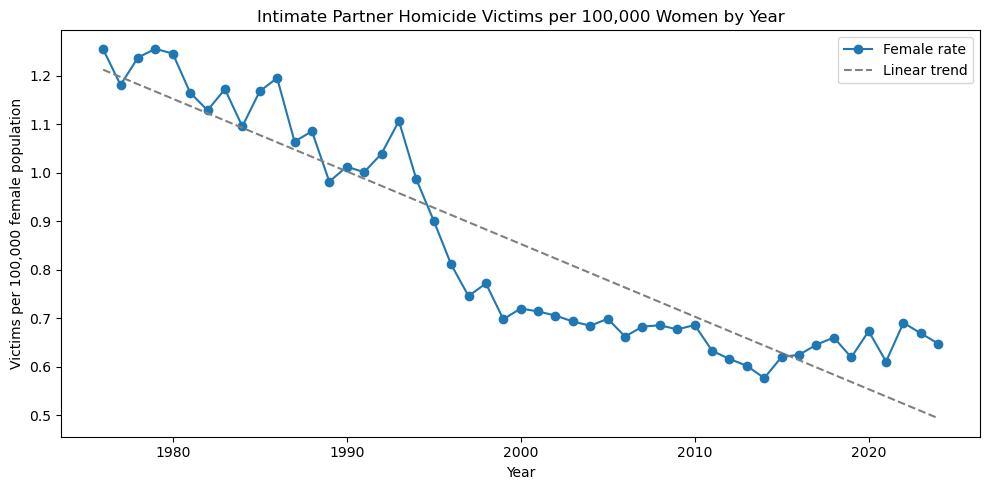

In [4]:
import numpy as np

female_rate = rates["Female"]
change = female_rate.diff()
pct_change = female_rate.pct_change() * 100

slope, intercept = np.polyfit(female_rate.index.astype(float), female_rate.values, 1)

trend = pd.DataFrame({
    "Female per 100k": female_rate.round(3),
    "Change from prior year": change.round(3),
    "Percent change (%)": pct_change.round(2),
})
print(trend)
print(f"\nLinear trend: {slope:+.4f} per 100k per year")
print(f"First to last year: {female_rate.iloc[0]:.3f} -> {female_rate.iloc[-1]:.3f} "
      f"({(female_rate.iloc[-1] / female_rate.iloc[0] - 1) * 100:+.1f}%)")

ax = female_rate.plot(kind="line", marker="o", figsize=(10, 5), label="Female rate")
ax.plot(female_rate.index, intercept + slope * female_rate.index.astype(float),
        linestyle="--", color="gray", label="Linear trend")
ax.set(
    title="Intimate Partner Homicide Victims per 100,000 Women by Year",
    xlabel="Year",
    ylabel="Victims per 100,000 female population",
)
ax.legend()
plt.tight_layout()
plt.show()

Checking for duplicates and data structure

In [6]:
import pandas as pd

df = pd.read_csv("shr_victims.csv", low_memory=False)
print("Rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())
print("Missing values per column (top 10):")
print(df.isna().sum().sort_values(ascending=False).head(10))

for col in ["victim_sex", "state_abb", "relation_to_offender_1", "victim_race"]:
    print(f"\n{col}:")
    print(df[col].astype("string").str.strip().value_counts(dropna=False).head(40))

print("\nYears:", sorted(df["year"].dropna().unique()))
print("\nRows per year:")
print(df["year"].value_counts().sort_index())

pop = pd.read_csv("population_state_year.csv", low_memory=False)
print("\nPopulation years:", sorted(pop["year"].dropna().unique()))
print("States in victims but not population:",
      sorted(set(df["state_abb"].dropna()) - set(pop["state_abb"].dropna())))

Rows: 877468
Duplicate rows: 88
Missing values per column (top 10):
victim_ethnic_origin       314359
county_name                 75252
offender_1_age              46954
is_intimate_partner         44618
relation_to_offender_1      44618
victim_age                  13301
offender_1_weapon            2825
offender_1_sex               2825
offender_1_circumstance      2825
agency_type                  1939
dtype: int64

victim_sex:
victim_sex
male       680119
female     195740
unknown      1609
Name: count, dtype: Int64

state_abb:
state_abb
CA    129536
TX     88228
NY     62618
MI     39316
IL     39218
PA     35346
GA     30514
NC     30434
OH     28935
LA     27447
MD     24168
TN     23186
MO     23040
VA     23027
FL     22450
NJ     19017
AZ     18276
SC     18166
IN     17261
AL     15319
OK     12849
WA     11671
KY     11342
CO     10496
AR     10495
WI     10054
MS      9085
NV      8445
DC      8443
MA      8324
CT      6686
NM      6557
OR      6459
MN      6282
KS      494

In [ ]:
Duplicates

In [10]:
import pandas as pd

df = pd.read_csv("shr_victims.csv", low_memory=False)
print(df[["incident_number", "victim_num"]].isna().sum())
print("Unique incident_number:", df["incident_number"].nunique(dropna=True))
print("Unique incident+victim (non-null):",
      df.dropna(subset=["incident_number", "victim_num"])
        .drop_duplicates(subset=["incident_number", "victim_num"]).shape[0])

incident_number    0
victim_num         0
dtype: int64
Unique incident_number: 581
Unique incident+victim (non-null): 1308


In [11]:
import pandas as pd

df = pd.read_csv("shr_victims.csv", low_memory=False)
key = ["ori", "year", "month", "incident_number", "victim_num"]

print("Rows:", len(df))
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate victim keys:", df.duplicated(subset=key).sum())
print("Duplicate keys with same victim fields:",
      df.duplicated(subset=key + ["victim_sex", "victim_age_raw", "victim_race"]).sum())
print("Max victims per incident:",
      df.groupby(["ori", "year", "month", "incident_number"])["victim_num"].nunique().max())

Rows: 877468
Exact duplicate rows: 88
Duplicate victim keys: 225
Duplicate keys with same victim fields: 124
Max victims per incident: 11


In [1]:
import pandas as pd

df = pd.read_csv("shr_victims.csv", low_memory=False)
key = ["ori", "year", "month", "incident_number", "victim_num"]
victim_fields = key + ["victim_sex", "victim_age_raw", "victim_race"]

conflict = df[df.duplicated(subset=key, keep=False) & ~df.duplicated(subset=victim_fields, keep=False)]
print("Rows with conflicting victim details:", len(conflict))
print(conflict[key + ["victim_sex", "victim_age_raw", "victim_race", "relation_to_offender_1"]].head(12))

clean = df.drop_duplicates(subset=victim_fields, keep="first")
print("Rows before:", len(df), "after:", len(clean))
clean.to_csv("shr_victims_clean.csv", index=False)

Rows with conflicting victim details: 191
          ori  year  month  incident_number  victim_num victim_sex  \
1892  CA01942  2024  march                3           1       male   
1897  CA01942  2024  march                3           1       male   
1905  CA01942  2024  april                4           1       male   
1907  CA01942  2024  april                4           1       male   
1910  CA01942  2024  march                5           1       male   
1911  CA01942  2024  april                5           1       male   
1915  CA01942  2024  april                5           1       male   
1916  CA01942  2024  march                5           1       male   
1933  CA01942  2024  march                8           1       male   
1935  CA01942  2024  april                8           1       male   
1939  CA01942  2024  april                8           1       male   
1940  CA01942  2024  march                8           1       male   

     victim_age_raw victim_race   relation_to_o

The average per day is the number of victims divided by the number of days in the period. For this project, count women killed by men, which matches the project's definition.

\text{Average per day} = \frac{\text{female victims killed by male offenders}}{\text{total days in the period}}

In [9]:
import pandas as pd

df = pd.read_csv("shr_victims_clean.csv", low_memory=False)
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df.dropna(subset=["year"])
df["year"] = df["year"].astype(int)

female = df["victim_sex"].astype("string").str.strip().str.lower().isin(["female", "f", "woman"])
male_offender = df["offender_1_sex"].astype("string").str.strip().str.lower().isin(["male", "m"])
fem_by_men = df[female & male_offender]

start, end = df["year"].min(), df["year"].max()
total_days = (pd.Timestamp(end, 12, 31) - pd.Timestamp(start, 1, 1)).days + 1

print(f"Period: {start}-{end} ({total_days:,} days)")
print(f"Female victims, male offenders: {len(fem_by_men):,}")
print(f"Average per day (overall): {len(fem_by_men) / total_days:.3f}")

annual = fem_by_men.groupby("year").size()
days = pd.Series([pd.Timestamp(y, 12, 31).dayofyear for y in annual.index], index=annual.index)
daily_by_year = (annual / days).round(3)
print("\nAverage per day, by year:")
print(daily_by_year)

Period: 1976-2024 (17,898 days)
Female victims, male offenders: 136,417
Average per day (overall): 7.622

Average per day, by year:
year
1976    7.869
1977    8.189
1978    8.600
1979    8.945
1980    8.948
1981    8.416
1982    8.567
1983    8.430
1984    8.281
1985    8.644
1986    9.049
1987    8.655
1988    8.462
1989    8.351
1990    8.395
1991    8.540
1992    9.085
1993    9.868
1994    8.951
1995    8.740
1996    7.230
1997    6.751
1998    6.627
1999    6.192
2000    6.273
2001    6.633
2002    6.622
2003    6.414
2004    6.235
2005    6.564
2006    6.496
2007    6.545
2008    6.404
2009    6.532
2010    6.304
2011    6.115
2012    6.199
2013    5.871
2014    5.830
2015    6.233
2016    6.650
2017    6.805
2018    7.041
2019    6.742
2020    8.505
2021    8.614
2022    9.984
2023    9.123
2024    8.954
dtype: float64


Analyzing the Femicide pattern with socio-economic data.

Checking the data quality of the census_file

In [10]:
import pandas as pd

FILE = "census_metrics_long.csv"
df = pd.read_csv(FILE, low_memory=False)

print("Shape:", df.shape)
print("\nColumns and types:")
print(df.dtypes)
print("\nSample rows:")
print(df.head(5).to_string())

print("\nMissing values:")
print(df.isna().sum()[lambda s: s > 0])
print("\nExact duplicate rows:", df.duplicated().sum())

def find(*words):
    for c in df.columns:
        if any(w in c.lower() for w in words):
            return c
    return None

STATE = find("state")
YEAR = find("year")
METRIC = find("metric", "variable", "indicator", "measure", "name")
VALUE = find("value", "estimate")
print("\nDetected:", {"state": STATE, "year": YEAR, "metric": METRIC, "value": VALUE})

if METRIC:
    print("\nMetric labels:")
    print(df[METRIC].astype("string").str.strip().value_counts(dropna=False))
if STATE:
    print("\nState values (first 60):")
    print(df[STATE].astype("string").str.strip().value_counts(dropna=False).head(60))
if YEAR:
    print("\nYears:", sorted(pd.to_numeric(df[YEAR], errors="coerce").dropna().unique().astype(int)))

if VALUE:
    v = pd.to_numeric(df[VALUE], errors="coerce")
    print("\nNon-numeric values in", VALUE, ":", (v.isna() & df[VALUE].notna()).sum())
    print(v.describe())

if STATE and YEAR and METRIC:
    key = [STATE, YEAR, METRIC]
    print("\nDuplicate state-year-metric keys:", df.duplicated(subset=key).sum())
    print(df[df.duplicated(subset=key, keep=False)].sort_values(key).head(10).to_string())

Shape: (1186049, 9)

Columns and types:
source         object
dataset        object
geo_level      object
geo_id          int64
state_fips      int64
name           object
year            int64
metric         object
value         float64
dtype: object

Sample rows:
  source                   dataset geo_level  geo_id  state_fips            name  year                   metric    value
0  SAIPE  timeseries/poverty/saipe    county    1001           1  Autauga County  2010       child_poverty_rate     17.5
1  SAIPE  timeseries/poverty/saipe    county    1001           1  Autauga County  2019       child_poverty_rate     15.9
2  SAIPE  timeseries/poverty/saipe    county    1001           1  Autauga County  2013  median_household_income  51868.0
3  SAIPE  timeseries/poverty/saipe    county    1001           1  Autauga County  2004  median_household_income  45379.0
4  SAIPE  timeseries/poverty/saipe    county    1001           1  Autauga County  2021  median_household_income  66444.0

Missing

In [11]:
import pandas as pd

FILE = "census_metrics_long.csv"

FIPS_TO_ABB = {
    1: "AL", 2: "AK", 4: "AZ", 5: "AR", 6: "CA", 8: "CO", 9: "CT", 10: "DE", 11: "DC",
    12: "FL", 13: "GA", 15: "HI", 16: "ID", 17: "IL", 18: "IN", 19: "IA", 20: "KS",
    21: "KY", 22: "LA", 23: "ME", 24: "MD", 25: "MA", 26: "MI", 27: "MN", 28: "MS",
    29: "MO", 30: "MT", 31: "NE", 32: "NV", 33: "NH", 34: "NJ", 35: "NM", 36: "NY",
    37: "NC", 38: "ND", 39: "OH", 40: "OK", 41: "OR", 42: "PA", 44: "RI", 45: "SC",
    46: "SD", 47: "TN", 48: "TX", 49: "UT", 50: "VT", 51: "VA", 53: "WA", 54: "WV",
    55: "WI", 56: "WY",
}

df = pd.read_csv(FILE, low_memory=False)
print("Geo levels:", df["geo_level"].value_counts().to_dict())

df = df[df["geo_level"].str.strip().str.lower() == "state"].copy()
df["state_abb"] = df["state_fips"].map(FIPS_TO_ABB)
print("Rows without a state abbreviation (territories, dropped):", df["state_abb"].isna().sum())
df = df.dropna(subset=["state_abb"])

df["metric"] = df["metric"].astype("string").str.strip()
df["value"] = pd.to_numeric(df["value"], errors="coerce")

print("\nRows per metric (with source and year range):")
print(df.groupby(["source", "metric"]).agg(
    rows=("value", "size"),
    missing=("value", lambda s: s.isna().sum()),
    year_min=("year", "min"),
    year_max=("year", "max"),
).to_string())

key = ["state_abb", "year", "metric"]
dups = df.duplicated(subset=key, keep=False)
print("\nRows sharing a state-year-metric key:", dups.sum())
if dups.any():
    print(df[dups].sort_values(key).head(10).to_string())

df = df.drop_duplicates(subset=key + ["source", "dataset"], keep="first")
df = df.dropna(subset=["value"])

clean = df[["state_abb", "year", "metric", "value", "source"]].sort_values(["state_abb", "year", "metric"])
clean.to_csv("census_state_clean.csv", index=False)
print("\nClean rows:", len(clean))
print("Years:", clean["year"].min(), "to", clean["year"].max())
print("States:", clean["state_abb"].nunique())

Geo levels: {'county': 923571, 'place': 239840, 'state': 22638}
Rows without a state abbreviation (territories, dropped): 198

Rows per metric (with source and year range):
                                            rows  missing  year_min  year_max
source      metric                                                           
ACS1        pct_ba_plus_25                  1020        0      2005      2025
            pct_ba_plus_25_female           1020        0      2005      2025
            pct_hs_plus_25                  1020        0      2005      2025
            pct_hs_plus_25_female           1020        0      2005      2025
            population                      1020        0      2005      2025
            population_female               1020        0      2005      2025
            poverty_rate                    1020        0      2005      2025
            poverty_rate_female             1020        0      2005      2025
            uninsured_rate                   86

Selects census metrics. It keeps one source per metric (SAIPE for poverty and income, ACS1 for education, insurance, and female-specific measures) so the same state-year isn't counted twice.
Reshapes the census data. It pivots from long format (one row per metric) to wide format (one row per state-year, one column per metric).
Computes the female victim rate. It counts female victims by state and year from the SHR file, divides by the female population from population_state_year.csv, and multiplies by 100,000.
Merges everything. It joins the rate to the census metrics on state and year.
Measures association. For each metric, it calculates a Spearman rank correlation with the female victim rate. Values near 1 or -1 indicate a strong monotonic relationship, and values near 0 indicate little relationship.
Saves the result. It writes the merged table to state_year_female_rate_socioeconomic.csv for further analysis.

In [12]:
import pandas as pd

PREFERRED = {
    "SAIPE": ["poverty_rate", "people_in_poverty", "child_poverty_rate", "median_household_income"],
    "ACS1": ["poverty_rate_female", "pct_hs_plus_25", "pct_hs_plus_25_female",
             "pct_ba_plus_25", "pct_ba_plus_25_female", "uninsured_rate",
             "uninsured_rate_female", "population_female"],
}

census = pd.read_csv("census_state_clean.csv", low_memory=False)
census = pd.concat([
    census[(census["source"] == src) & (census["metric"].isin(metrics))]
    for src, metrics in PREFERRED.items()
], ignore_index=True)

dups = census.duplicated(subset=["state_abb", "year", "metric"]).sum()
print("Duplicate state-year-metric keys after source selection:", dups)

wide = census.pivot(index=["state_abb", "year"], columns="metric", values="value").reset_index()

shr = pd.read_csv("shr_victims_clean.csv", low_memory=False,
                  usecols=["state_abb", "year", "victim_sex"])
shr["year"] = pd.to_numeric(shr["year"], errors="coerce")
shr = shr[shr["victim_sex"].astype("string").str.strip().str.lower().isin(["female", "f", "woman"])]
victims = shr.groupby(["state_abb", "year"]).size().rename("female_victims").reset_index()

pop = pd.read_csv("population_state_year.csv", low_memory=False,
                  usecols=["state_abb", "year", "pop_female"])
pop["year"] = pd.to_numeric(pop["year"], errors="coerce").astype(int)

rates = victims.merge(pop, on=["state_abb", "year"], how="inner")
rates["female_rate_100k"] = rates["female_victims"] / rates["pop_female"] * 100_000

merged = rates.merge(wide, on=["state_abb", "year"], how="inner")
print("Matched state-years:", len(merged))
print("Years:", merged["year"].min(), "to", merged["year"].max())

metric_cols = [c for c in wide.columns if c not in ("state_abb", "year")]
results = []
for m in metric_cols:
    sub = merged[["female_rate_100k", m]].dropna()
    if len(sub) > 2:
        results.append({
            "metric": m,
            "n": len(sub),
            "spearman_rho": sub["female_rate_100k"].corr(sub[m], method="spearman"),
        })
print("\nRank correlation with female victim rate:")
print(pd.DataFrame(results).sort_values("spearman_rho").round(3).to_string(index=False))

merged.to_csv("state_year_female_rate_socioeconomic.csv", index=False)
print("\nSaved: state_year_female_rate_socioeconomic.csv")

Duplicate state-year-metric keys after source selection: 0
Matched state-years: 1586
Years: 1989 to 2024

Rank correlation with female victim rate:
                 metric    n  spearman_rho
         pct_ba_plus_25  950        -0.216
         pct_hs_plus_25  950        -0.192
  pct_hs_plus_25_female  950        -0.171
median_household_income 1586        -0.162
  pct_ba_plus_25_female  950        -0.161
      population_female  950         0.059
  uninsured_rate_female  754         0.136
         uninsured_rate  803         0.137
      people_in_poverty 1586         0.216
           poverty_rate 1586         0.344
    poverty_rate_female  950         0.350
     child_poverty_rate 1586         0.368

Saved: state_year_female_rate_socioeconomic.csv


Analyzing the Socio-economic conditions of the female victims

All correlations are weak to moderate, with absolute values at or below 0.37. Female victim rates are higher in state-years with higher child poverty (0.37), poverty (0.34 to 0.35), and people in poverty (0.22). They are lower in state-years with higher bachelor's-degree attainment (-0.22) and high-school attainment (-0.19), and with higher median household income (-0.16).

Before you write this up:

Shared time trends. Female victim rates fell from 1989 to 2024, and poverty and education levels changed over the same years. Correlations can reflect these common trends rather than a direct link. Try correlating year-over-year changes, or adding a year term to a regression.
Mixed sources and years. Poverty and income come from SAIPE (1989 to 2024), while education and female-specific measures come from ACS (2005 onward). The sample sizes differ (950 vs. 1,586), so the metrics aren't directly comparable.
Non-independent observations. The same state appears in many years, so the 1,586 state-years aren't independent. Report the state count and consider state-level clustering.
Victim definition. The merge uses all female victims in the SHR file. Your project's definition is women killed by men, so use the male-offender filter from the daily-rate script to match it.


                                            label    n    rho
  Adults 25+ with bachelor's degree or higher (%)  950 -0.216
Adults 25+ with high school diploma or higher (%)  950 -0.192
 Women 25+ with high school diploma or higher (%)  950 -0.171
                      Median household income ($) 1586 -0.162
   Women 25+ with bachelor's degree or higher (%)  950 -0.161
                        Female population (count)  950  0.059
               Women without health insurance (%)  754  0.136
              People without health insurance (%)  803  0.137
                      Number of people in poverty 1586  0.216
                            People in poverty (%) 1586  0.344
                             Women in poverty (%)  950  0.350
                          Children in poverty (%) 1586  0.368


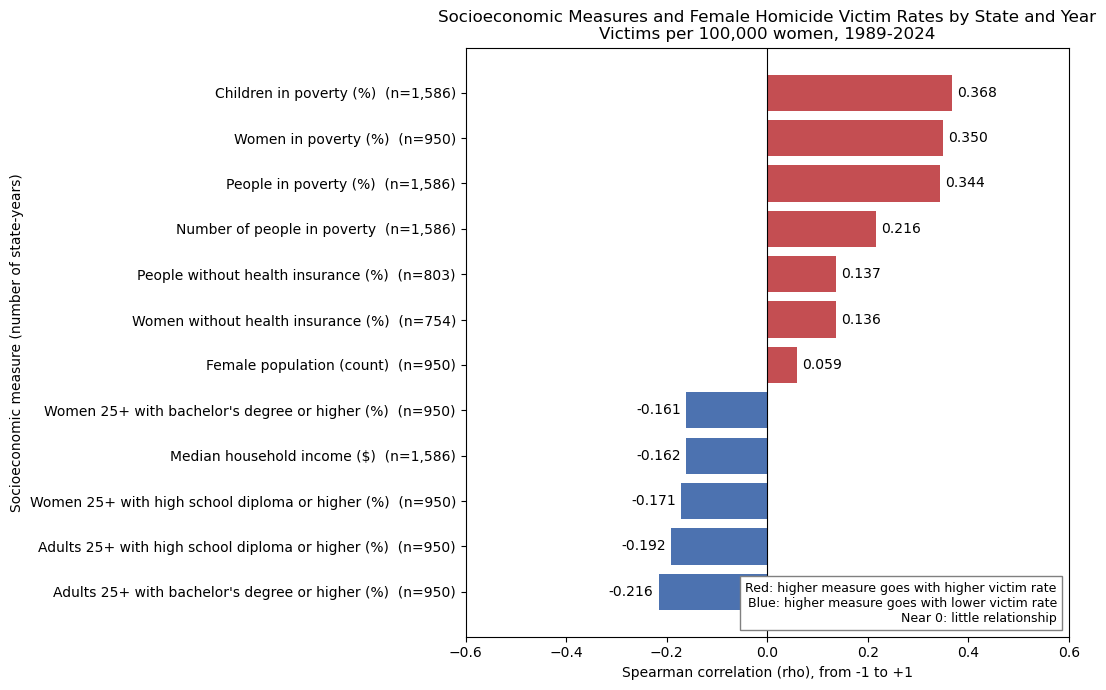

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

FILE = "state_year_female_rate_socioeconomic.csv"
RATE_COL = "female_rate_100k"
SKIP = {"state_abb", "year", "female_victims", "pop_female", RATE_COL}

LABELS = {
    "pct_ba_plus_25": "Adults 25+ with bachelor's degree or higher (%)",
    "pct_ba_plus_25_female": "Women 25+ with bachelor's degree or higher (%)",
    "pct_hs_plus_25": "Adults 25+ with high school diploma or higher (%)",
    "pct_hs_plus_25_female": "Women 25+ with high school diploma or higher (%)",
    "median_household_income": "Median household income ($)",
    "poverty_rate": "People in poverty (%)",
    "poverty_rate_female": "Women in poverty (%)",
    "child_poverty_rate": "Children in poverty (%)",
    "people_in_poverty": "Number of people in poverty",
    "uninsured_rate": "People without health insurance (%)",
    "uninsured_rate_female": "Women without health insurance (%)",
    "population_female": "Female population (count)",
}

df = pd.read_csv(FILE, low_memory=False)
metrics = [c for c in df.columns if c not in SKIP and pd.api.types.is_numeric_dtype(df[c])]

rows = []
for m in metrics:
    sub = df[[RATE_COL, m]].dropna()
    if len(sub) > 2:
        rows.append({
            "label": LABELS.get(m, m),
            "n": len(sub),
            "rho": sub[RATE_COL].corr(sub[m], method="spearman"),
        })

res = pd.DataFrame(rows).sort_values("rho")
print(res.round(3).to_string(index=False))

y_labels = [f"{l}  (n={n:,})" for l, n in zip(res["label"], res["n"])]
colors = ["#C44E52" if r > 0 else "#4C72B0" for r in res["rho"]]

fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(y_labels, res["rho"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-0.6, 0.6)
ax.set_xlabel("Spearman correlation (rho), from -1 to +1")
ax.set_ylabel("Socioeconomic measure (number of state-years)")
ax.set_title(
    "Socioeconomic Measures and Female Homicide Victim Rates by State and Year\n"
    "Victims per 100,000 women, 1989-2024"
)
for bar, r in zip(bars, res["rho"]):
    ax.text(r + (0.01 if r >= 0 else -0.01), bar.get_y() + bar.get_height() / 2,
            f"{r:.3f}", va="center", ha="left" if r >= 0 else "right")
ax.text(0.98, 0.02,
        "Red: higher measure goes with higher victim rate\n"
        "Blue: higher measure goes with lower victim rate\n"
        "Near 0: little relationship",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=9,
        bbox=dict(facecolor="white", edgecolor="gray"))
plt.tight_layout()
plt.show()

Analyzing the socio-economic conditions of male offenders

Male offenders by age group (% of known ages):
age_group
under 18     8.0
18-24       30.8
25-34       30.1
35-44       16.3
45-54        8.3
55-64        4.0
65+          2.5
Name: proportion, dtype: float64

Top offender circumstances:
offender_1_circumstance
other arguments                                      183139
unknown                                               85950
other non-felony type - not specified                 78799
robbery                                               40444
narcotic drug laws                                    19527
felon killed by police                                16355
argument over money or property                       13535
brawl due to influence of alcohol                     13404
felon killed by private citizen                       12736
juvenile gang killings                                12683
other felony type - not specified                     11209
all other manslaughter by negligence except tr...      9155
Name: count, dtype

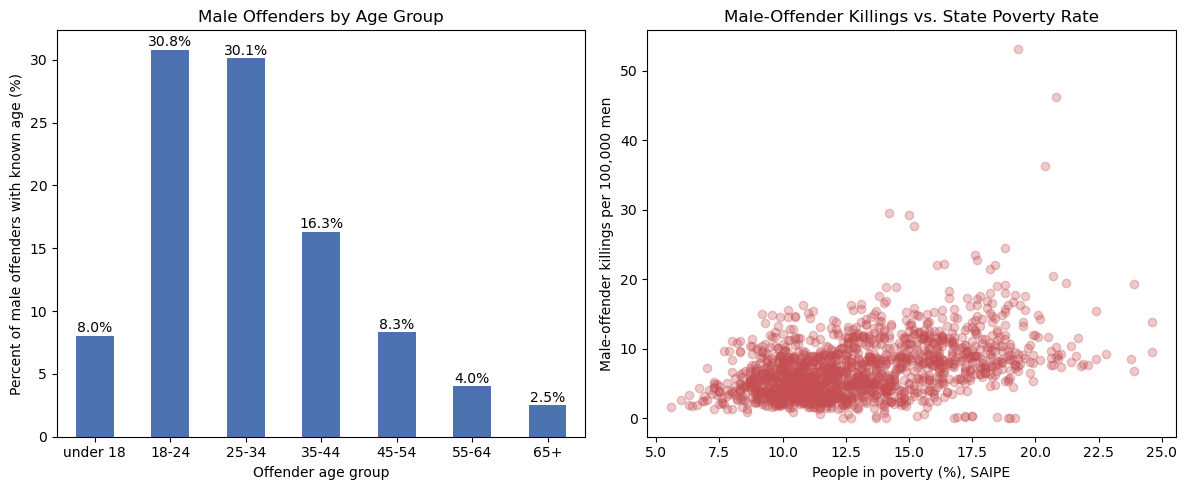

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SHR_FILE = "shr_victims_clean.csv"
CENSUS_FILE = "census_state_clean.csv"
POP_FILE = "population_state_year.csv"

shr = pd.read_csv(SHR_FILE, low_memory=False)
shr["year"] = pd.to_numeric(shr["year"], errors="coerce")
male_off = shr["offender_1_sex"].astype("string").str.strip().str.lower().isin(["male", "m"])
off = shr[male_off].copy()
off["offender_age"] = pd.to_numeric(off["offender_1_age"], errors="coerce")

bins = [0, 17, 24, 34, 44, 54, 64, 120]
labels = ["under 18", "18-24", "25-34", "35-44", "45-54", "55-64", "65+"]
off["age_group"] = pd.cut(off["offender_age"], bins=bins, labels=labels, right=True)
age_dist = off["age_group"].value_counts(normalize=True, sort=False).mul(100).round(1)
print("Male offenders by age group (% of known ages):")
print(age_dist)

circ = off["offender_1_circumstance"].astype("string").str.strip().value_counts().head(12)
print("\nTop offender circumstances:")
print(circ)

off_state_year = off.groupby(["state_abb", "year"]).size().rename("male_offender_killings").reset_index()

census = pd.read_csv(CENSUS_FILE, low_memory=False)
census = census[(census["source"] == "SAIPE") &
                (census["metric"].isin(["poverty_rate", "median_household_income"]))]
wide = census.pivot_table(index=["state_abb", "year"], columns="metric", values="value").reset_index()

pop = pd.read_csv(POP_FILE, low_memory=False, usecols=["state_abb", "year", "pop_male"])
pop["year"] = pd.to_numeric(pop["year"], errors="coerce").astype(int)

m = off_state_year.merge(wide, on=["state_abb", "year"]).merge(pop, on=["state_abb", "year"])
m["male_offender_rate_100k"] = m["male_offender_killings"] / m["pop_male"] * 100_000
print(f"\nMatched state-years: {len(m)}")

rows = []
for col in ["poverty_rate", "median_household_income"]:
    rho = m["male_offender_rate_100k"].corr(m[col], method="spearman")
    rows.append({"measure": col, "n": len(m), "spearman_rho": round(rho, 3)})
res = pd.DataFrame(rows)
print(res.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
age_dist.plot(kind="bar", ax=axes[0], color="#4C72B0", rot=0)
axes[0].set(title="Male Offenders by Age Group", xlabel="Offender age group",
            ylabel="Percent of male offenders with known age (%)")
for i, v in enumerate(age_dist.values):
    axes[0].text(i, v + 0.3, f"{v:.1f}%", ha="center")

axes[1].scatter(m["poverty_rate"], m["male_offender_rate_100k"], alpha=0.3, color="#C44E52")
axes[1].set(title="Male-Offender Killings vs. State Poverty Rate",
            xlabel="People in poverty (%), SAIPE", ylabel="Male-offender killings per 100,000 men")
plt.tight_layout()
plt.show()

Female victims with male offender and known ages: 60,303

Victims by age group:
victim_group
Under 18     5752
18-24        9116
25-34       13201
35-44       11977
45-54        8721
55-64        5373
65+          6163

Row percentages (offender age, within each victim age group):
offender_group  Under 18  18-24  25-34  35-44  45-54  55-64   65+
victim_group                                                     
Under 18            13.9   34.2   27.8   15.1    6.4    2.0   0.5
18-24                4.2   47.4   33.4    9.5    3.4    1.7   0.4
25-34                1.8   13.8   46.8   26.5    7.6    2.7   0.8
35-44                2.5    9.5   18.3   40.3   21.9    6.0   1.6
45-54                2.5   11.1   15.9   17.5   34.1   15.0   3.9
55-64                2.3   10.6   19.3   15.7   15.2   25.8  11.0
65+                  2.7    9.7   14.3   14.8   14.4    9.5  34.6


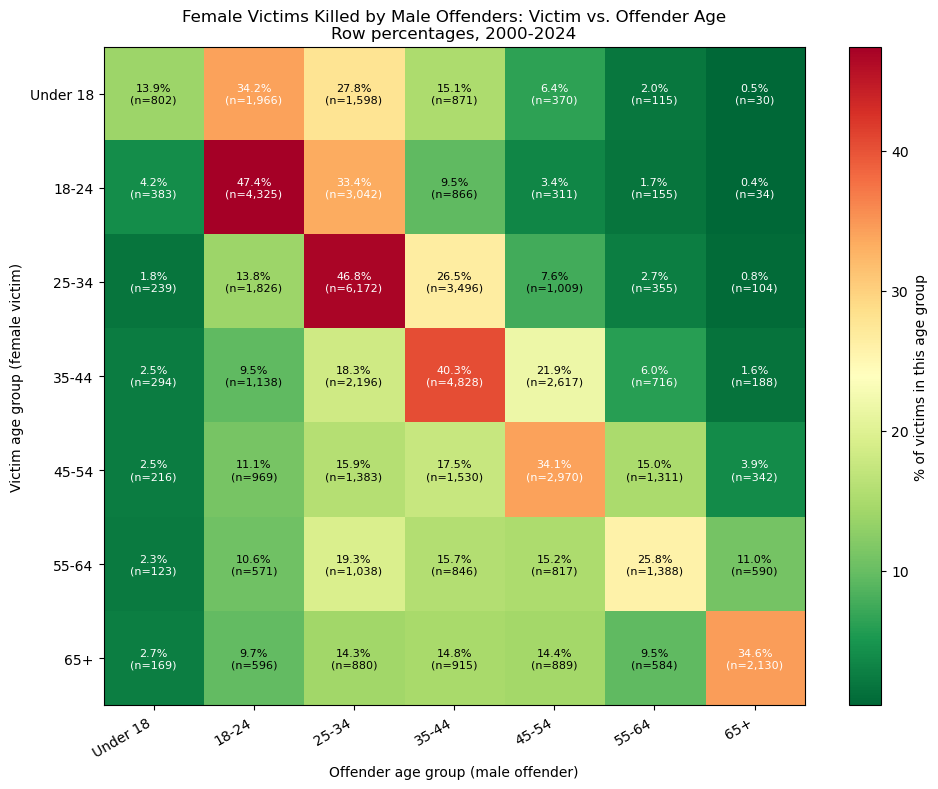

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FILE = "shr_victims_clean.csv"
YEAR_MIN, YEAR_MAX = 2000, 2024
BINS = [0, 17, 24, 34, 44, 54, 64, 120]
LABELS = ["Under 18", "18-24", "25-34", "35-44", "45-54", "55-64", "65+"]

df = pd.read_csv(FILE, low_memory=False,
                 usecols=["year", "victim_sex", "offender_1_sex", "victim_age_raw", "offender_1_age"])
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df[df["year"].between(YEAR_MIN, YEAR_MAX)]

sex = df["victim_sex"].astype("string").str.strip().str.lower()
off = df["offender_1_sex"].astype("string").str.strip().str.lower()
f = df[sex.isin(["female", "f", "woman"]) & off.isin(["male", "m"])].copy()

f["victim_group"] = pd.cut(pd.to_numeric(f["victim_age_raw"], errors="coerce"), BINS, labels=LABELS)
f["offender_group"] = pd.cut(pd.to_numeric(f["offender_1_age"], errors="coerce"), BINS, labels=LABELS)
f = f.dropna(subset=["victim_group", "offender_group"])

ct = pd.crosstab(f["victim_group"], f["offender_group"]).reindex(index=LABELS, columns=LABELS, fill_value=0)
pct = ct.div(ct.sum(axis=1), axis=0) * 100

print(f"Female victims with male offender and known ages: {len(f):,}")
print("\nVictims by age group:")
print(ct.sum(axis=1).to_string())
print("\nRow percentages (offender age, within each victim age group):")
print(pct.round(1).to_string())

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(pct.values, cmap="RdYlGn_r", aspect="auto")
ax.set_xticks(range(len(LABELS)), labels=LABELS, rotation=30, ha="right")
ax.set_yticks(range(len(LABELS)), labels=LABELS)
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        ax.text(j, i, f"{pct.values[i, j]:.1f}%\n(n={ct.values[i, j]:,})",
                ha="center", va="center", fontsize=8,
                color="white" if (pct.values[i, j] > pct.values.max() * 0.6 or pct.values[i, j] < pct.values.max() * 0.15) else "black",)
ax.set(xlabel="Offender age group (male offender)", ylabel="Victim age group (female victim)",
       title=f"Female Victims Killed by Male Offenders: Victim vs. Offender Age\n"
             f"Row percentages, {YEAR_MIN}-{YEAR_MAX}")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("% of victims in this age group")
plt.tight_layout()
plt.savefig("female_victim_offender_age_heatmap.png", dpi=150)
plt.show()

This heatmap shows, for female victims killed by male offenders, the share of each victim age group whose offender fell in each age group. Each row sums to 100%. Cell labels show the percent and the count.

Statewise poverty

In [22]:
import pandas as pd
import plotly.express as px

CENSUS_FILE = "census_state_clean.csv"
METRIC = "poverty_rate"
SOURCE = "SAIPE"

df = pd.read_csv(CENSUS_FILE, low_memory=False)
df = df[(df["source"] == SOURCE) & (df["metric"] == METRIC)].copy()
df["year"] = pd.to_numeric(df["year"], errors="coerce").astype(int)
df = df.dropna(subset=["state_abb", "value"]).sort_values(["year", "state_abb"])

print(f"State-years: {len(df):,}, years {df['year'].min()}-{df['year'].max()}")

fig = px.choropleth(
    df,
    locations="state_abb",
    locationmode="USA-states",
    color="value",
    animation_frame="year",
    scope="usa",
    color_continuous_scale="Reds",
    range_color=(df["value"].min(), df["value"].max()),
    labels={"value": "People in poverty (%)", "state_abb": "State"},
    hover_name="state_abb",
    title="People in Poverty (%) by State, 1989-2024<br>"
          "<sup>Source: Census SAIPE. Use the slider to change the year.</sup>",
)
fig.update_layout(
    coloraxis_colorbar=dict(title="Poverty (%)"),
    margin=dict(l=10, r=10, t=90, b=10),
    height=650,
)

fig.write_html("state_poverty_map.html")
fig.show()

State-years: 1,632, years 1989-2024


Green-to-red poverty scale and makes bubble diameter proportional to the female victim rate per 100,000 women

In [26]:
import pandas as pd
import plotly.graph_objects as go

SHR_FILE = "shr_victims_clean.csv"
CENSUS_FILE = "census_state_clean.csv"
POP_FILE = "population_state_year.csv"
MAX_BUBBLE_PX = 40

shr = pd.read_csv(SHR_FILE, low_memory=False,
                  usecols=["state_abb", "year", "victim_sex", "offender_1_sex"])
shr["year"] = pd.to_numeric(shr["year"], errors="coerce").astype("Int64")
sex = shr["victim_sex"].astype("string").str.strip().str.lower()
off = shr["offender_1_sex"].astype("string").str.strip().str.lower()
f = shr[sex.isin(["female", "f", "woman"]) & off.isin(["male", "m"])]
cnt = f.groupby(["state_abb", "year"]).size().rename("fem_victims").reset_index()
cnt["year"] = cnt["year"].astype(int)

pop = pd.read_csv(POP_FILE, low_memory=False, usecols=["state_abb", "year", "pop_female"])
pop["year"] = pd.to_numeric(pop["year"], errors="coerce").astype(int)

census = pd.read_csv(CENSUS_FILE, low_memory=False)
pov = census[(census["source"] == "SAIPE") & (census["metric"] == "poverty_rate")]
pov = pov[["state_abb", "year", "value"]].rename(columns={"value": "poverty_rate"})
pov["year"] = pd.to_numeric(pov["year"], errors="coerce").astype(int)

sy = pov.merge(pop, on=["state_abb", "year"], how="inner")
sy = sy.merge(cnt, on=["state_abb", "year"], how="left")
sy["fem_victims"] = sy["fem_victims"].fillna(0).astype(int)
sy["fem_rate_100k"] = sy["fem_victims"] / sy["pop_female"] * 100_000
sy = sy.sort_values(["year", "state_abb"])
sy.to_csv("state_year_map_data.csv", index=False)

years = sorted(sy["year"].unique())
rmax = sy["fem_rate_100k"].max()
pmin, pmax = sy["poverty_rate"].min(), sy["poverty_rate"].max()

GREEN_RED = [
    [0.0, "#1a9850"],
    [0.5, "#fee08b"],
    [1.0, "#d73027"],
]

def bubble_size(r):
    return MAX_BUBBLE_PX * r / rmax

def frame_data(y):
    d = sy[sy["year"] == y]
    hover = [f"{s}<br>Poverty: {p:.1f}%<br>Female victims (male offender): {n}<br>Rate: {r:.2f} per 100k women"
             for s, p, n, r in zip(d["state_abb"], d["poverty_rate"], d["fem_victims"], d["fem_rate_100k"])]
    choro = go.Choropleth(
        locations=d["state_abb"], z=d["poverty_rate"], locationmode="USA-states",
        zmin=pmin, zmax=pmax, colorscale=GREEN_RED,
        colorbar=dict(title="Poverty (%)"),
        hoverinfo="skip",
    )
    bubbles = go.Scattergeo(
        locations=d["state_abb"], locationmode="USA-states",
        marker=dict(size=[bubble_size(r) for r in d["fem_rate_100k"]],
                    color="#4B0082", opacity=0.6,
                    line=dict(width=0.5, color="white")),
        text=hover, hoverinfo="text",
    )
    return [choro, bubbles]

frames = [go.Frame(data=frame_data(y), name=str(y), traces=[0, 1]) for y in years]

fig = go.Figure(data=frame_data(years[0]), frames=frames)
fig.update_layout(
    title=dict(
        text="Poverty Rate (green = low, red = high) and Female Victims Killed by Male Offenders per 100,000 Women (bubbles)<br>"
             "<sup>Bubble diameter is proportional to the rate per 100,000 women. Sources: Census SAIPE, FBI SHR, Census population. Use the slider for the year.</sup>",
        x=0.5),
    geo=dict(scope="usa", projection=dict(type="albers usa"), showlakes=True, lakecolor="white"),
    height=680,
    margin=dict(l=10, r=10, t=100, b=10),
    sliders=[dict(
        active=0,
        currentvalue=dict(prefix="Year: ", font=dict(size=16)),
        pad=dict(t=40),
        steps=[dict(method="animate", label=str(y),
                    args=[[str(y)], dict(mode="immediate", frame=dict(duration=0, redraw=True),
                                         transition=dict(duration=0))])
               for y in years],
    )],
    updatemenus=[dict(
        type="buttons", showactive=False, x=0.05, y=0, xanchor="left", yanchor="top",
        pad=dict(t=60, r=10),
        buttons=[dict(label="Play", method="animate",
                      args=[None, dict(frame=dict(duration=600, redraw=True),
                                       fromcurrent=True, transition=dict(duration=300))]),
                 dict(label="Pause", method="animate",
                      args=[[None], dict(frame=dict(duration=0, redraw=False),
                                         mode="immediate", transition=dict(duration=0))])],
    )],
)

fig.write_html("femicide_poverty_map.html")
fig.show()

In [27]:
import pandas as pd
import plotly.graph_objects as go

DATA_FILE = "state_year_map_data.csv"
MAX_BUBBLE_PX = 40

df = pd.read_csv(DATA_FILE, low_memory=False)

state = df.groupby("state_abb").agg(
    avg_poverty=("poverty_rate", "mean"),
    avg_rate_100k=("fem_rate_100k", "mean"),
    avg_count=("fem_victims", "mean"),
    years=("year", "nunique"),
).reset_index()
state.to_csv("state_avg_map_data.csv", index=False)

rho = state["avg_poverty"].corr(state["avg_rate_100k"], method="spearman")
print(state.round(2).sort_values("avg_rate_100k", ascending=False).to_string(index=False))
print(f"\nSpearman rho (state averages, poverty vs. rate): {rho:.3f}")

GREEN_RED = [[0.0, "#1a9850"], [0.5, "#fee08b"], [1.0, "#d73027"]]
rmax = state["avg_rate_100k"].max()

hover = [
    f"{s}<br>Average poverty: {p:.1f}%<br>Average female victims per year: {c:.1f}"
    f"<br>Average rate: {r:.2f} per 100k women"
    for s, p, c, r in zip(state["state_abb"], state["avg_poverty"],
                          state["avg_count"], state["avg_rate_100k"])
]

fig = go.Figure()
fig.add_trace(go.Choropleth(
    locations=state["state_abb"], z=state["avg_poverty"],
    locationmode="USA-states", colorscale=GREEN_RED,
    colorbar=dict(title="Avg poverty (%)"),
    hoverinfo="skip",
))
fig.add_trace(go.Scattergeo(
    locations=state["state_abb"], locationmode="USA-states",
    marker=dict(size=[MAX_BUBBLE_PX * r / rmax for r in state["avg_rate_100k"]],
                color="#4B0082", opacity=0.6, line=dict(width=0.5, color="white")),
    text=hover, hoverinfo="text",
))
fig.update_layout(
    title=dict(
        text="Average Poverty Rate (fill) and Average Female Victims Killed by Male Offenders (bubbles), 1989-2024<br>"
             "<sup>Fill: green = low poverty, red = high poverty. Bubble diameter is proportional to the average annual rate per 100,000 women.</sup>",
        x=0.5),
    geo=dict(scope="usa", projection=dict(type="albers usa"), showlakes=True, lakecolor="white"),
    height=680,
    margin=dict(l=10, r=10, t=100, b=10),
    showlegend=False,
)

fig.write_html("femicide_poverty_state_average_map.html")
fig.show()

state_abb  avg_poverty  avg_rate_100k  avg_count  years
       AK        10.25           3.43      11.28     32
       SC        15.36           3.29      75.41     32
       NV        12.15           3.08      37.25     32
       LA        19.28           3.07      70.97     32
       OK        15.84           2.85      52.62     32
       TN        15.15           2.66      85.03     32
       AR        17.10           2.65      38.25     32
       NC        14.25           2.42     111.19     32
       MO        13.28           2.40      71.84     32
       NM        18.66           2.36      23.72     32
       TX        16.07           2.29     277.91     32
       VA        10.46           2.27      88.69     32
       AZ        15.06           2.23      66.41     32
       GA        15.06           2.21     102.84     32
       WV        17.48           2.19      20.19     32
       MI        13.49           2.07     104.62     32
       CO        10.71           2.02      49.38

Map uses one value per state: the 1989–2024 average poverty rate for the fill color, and the average annual female victim rate per 100,000 women for the bubble size. 


Matched state-years: 1,584
                                            label    n    rho
  Adults 25+ with bachelor's degree or higher (%)  949 -0.251
   Women 25+ with bachelor's degree or higher (%)  949 -0.195
Adults 25+ with high school diploma or higher (%)  949 -0.165
                      Median household income ($) 1584 -0.162
 Women 25+ with high school diploma or higher (%)  949 -0.142
                        Female population (count)  949 -0.015
                      Number of people in poverty 1584  0.137
              People without health insurance (%)  802  0.174
               Women without health insurance (%)  753  0.177
                             Women in poverty (%)  949  0.339
                            People in poverty (%) 1584  0.340
                          Children in poverty (%) 1584  0.345


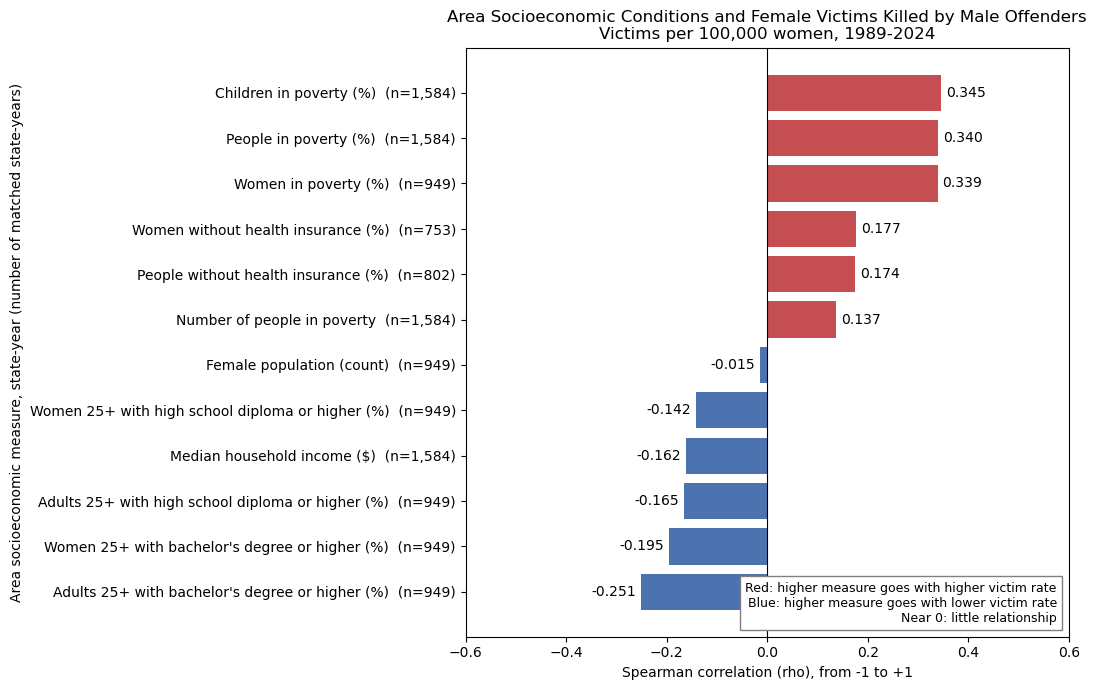

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

SHR_FILE = "shr_victims_clean.csv"
CENSUS_FILE = "census_state_clean.csv"
POP_FILE = "population_state_year.csv"
RATE_COL = "female_rate_by_male_offender_100k"

PREFERRED = {
    "SAIPE": ["poverty_rate", "people_in_poverty", "child_poverty_rate", "median_household_income"],
    "ACS1": ["poverty_rate_female", "pct_hs_plus_25", "pct_hs_plus_25_female",
             "pct_ba_plus_25", "pct_ba_plus_25_female", "uninsured_rate",
             "uninsured_rate_female", "population_female"],
}

LABELS = {
    "poverty_rate": "People in poverty (%)",
    "people_in_poverty": "Number of people in poverty",
    "child_poverty_rate": "Children in poverty (%)",
    "median_household_income": "Median household income ($)",
    "poverty_rate_female": "Women in poverty (%)",
    "pct_hs_plus_25": "Adults 25+ with high school diploma or higher (%)",
    "pct_hs_plus_25_female": "Women 25+ with high school diploma or higher (%)",
    "pct_ba_plus_25": "Adults 25+ with bachelor's degree or higher (%)",
    "pct_ba_plus_25_female": "Women 25+ with bachelor's degree or higher (%)",
    "uninsured_rate": "People without health insurance (%)",
    "uninsured_rate_female": "Women without health insurance (%)",
    "population_female": "Female population (count)",
}

census = pd.read_csv(CENSUS_FILE, low_memory=False)
census = pd.concat([
    census[(census["source"] == src) & (census["metric"].isin(metrics))]
    for src, metrics in PREFERRED.items()
], ignore_index=True)
wide = census.pivot(index=["state_abb", "year"], columns="metric", values="value").reset_index()

shr = pd.read_csv(SHR_FILE, low_memory=False,
                  usecols=["state_abb", "year", "victim_sex", "offender_1_sex"])
shr["year"] = pd.to_numeric(shr["year"], errors="coerce")
female_victim = shr["victim_sex"].astype("string").str.strip().str.lower().isin(["female", "f", "woman"])
male_offender = shr["offender_1_sex"].astype("string").str.strip().str.lower().isin(["male", "m"])
victims = (shr[female_victim & male_offender]
           .groupby(["state_abb", "year"]).size()
           .rename("female_victims_male_offender").reset_index())

pop = pd.read_csv(POP_FILE, low_memory=False, usecols=["state_abb", "year", "pop_female"])
pop["year"] = pd.to_numeric(pop["year"], errors="coerce").astype(int)

rates = victims.merge(pop, on=["state_abb", "year"], how="inner")
rates[RATE_COL] = rates["female_victims_male_offender"] / rates["pop_female"] * 100_000

merged = rates.merge(wide, on=["state_abb", "year"], how="inner")
merged.to_csv("state_year_female_by_male_offender_socioeconomic.csv", index=False)
print(f"Matched state-years: {len(merged):,}")

metric_cols = [c for c in wide.columns if c not in ("state_abb", "year")]
rows = []
for m in metric_cols:
    sub = merged[[RATE_COL, m]].dropna()
    if len(sub) > 2:
        rows.append({
            "label": LABELS.get(m, m),
            "n": len(sub),
            "rho": sub[RATE_COL].corr(sub[m], method="spearman"),
        })
res = pd.DataFrame(rows).sort_values("rho")
print(res.round(3).to_string(index=False))

y_labels = [f"{l}  (n={n:,})" for l, n in zip(res["label"], res["n"])]
colors = ["#C44E52" if r > 0 else "#4C72B0" for r in res["rho"]]

fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(y_labels, res["rho"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-0.6, 0.6)
ax.set_xlabel("Spearman correlation (rho), from -1 to +1")
ax.set_ylabel("Area socioeconomic measure, state-year (number of matched state-years)")
ax.set_title(
    "Area Socioeconomic Conditions and Female Victims Killed by Male Offenders\n"
    "Victims per 100,000 women, 1989-2024"
)
for bar, r in zip(bars, res["rho"]):
    ax.text(r + (0.01 if r >= 0 else -0.01), bar.get_y() + bar.get_height() / 2,
            f"{r:.3f}", va="center", ha="left" if r >= 0 else "right")
ax.text(0.98, 0.02,
        "Red: higher measure goes with higher victim rate\n"
        "Blue: higher measure goes with lower victim rate\n"
        "Near 0: little relationship",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=9,
        bbox=dict(facecolor="white", edgecolor="gray"))
plt.tight_layout()
plt.savefig("female_victims_male_offender_socioeconomic.png", dpi=150)
plt.show()

This chart shows how female victims killed by male offenders relate to conditions in their state and year. Each bar is a Spearman correlation (rho) between the female victim rate per 100,000 women and one area measure. Values range from -1 to +1.

Positive (red): higher value, higher victim rate

Children in poverty: 0.345
People in poverty: 0.340
Women in poverty: 0.339
Uninsured women and people: about 0.17
Number of people in poverty: 0.137
Negative (blue): higher value, lower victim rate

Adults 25+ with a bachelor's degree: -0.251
Women 25+ with a bachelor's degree: -0.195
Adults and women 25+ with a high school diploma: about -0.14 to -0.17
Median household income: -0.162
Near zero: Female population count (-0.015), so the size of a state's female population doesn't track the rate.

Pattern: States and years with higher poverty and lower education or income tend to have higher rates of women killed by male offenders. Poverty measures show the strongest positive links, and education shows the strongest negative link. All correlations are weak to moderate. The largest, about 0.35 or -0.25, explain roughly 6 to 12 percent of the rank variation (rho squared).

In [29]:
%pip install --upgrade plotly nbformat

  Obtaining dependency information for nbformat from https://files.pythonhosted.org/packages/1a/69/ee613f74085ca7103f79cd08d579c4f3177d1d26e5d3d9528d2d6536a707/nbformat-5.11.1-py3-none-any.whl.metadata
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.8/79.8 kB 2.9 MB/s eta 0:00:00a 0:00:01
  Attempting uninstall: nbformat
    Found existing installation: nbformat 5.11.0
    Uninstalling nbformat-5.11.0:
      Successfully uninstalled nbformat-5.11.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
conda-repo-cli 1.0.75 requires requests_mock, which is not installed.
spyder 5.4.3 requires pyqt5<5.16, which is not installed.
spyder 5.4.3 requires pyqtwebengine<5.16, which is not installed.
conda-repo-cli 1.0.75 requires clyent==1.2.1, but you have clyent 1.2.2 which is incompatible.
conda-repo-cli 1.0.75 requires nbformat==5.9.2, but you have nbformat 5.11.1 which i

In [31]:
import sys
import plotly
print(sys.executable)
print(plotly.__version__)

/Users/paulamibose/anaconda3/bin/python
7.1.0


In [34]:
import pandas as pd

SHR_FILE = "shr_victims_clean.csv"
POP_FILE = "population_state_year.csv"
MAP_FILE = "state_year_map_data.csv"
MIN_COVERAGE = 0.80

shr = pd.read_csv(SHR_FILE, low_memory=False,
                  usecols=["ori", "state_abb", "year", "victim_sex",
                           "offender_1_sex", "agency_population"])
shr["year"] = pd.to_numeric(shr["year"], errors="coerce").astype(int)

covered = (shr.drop_duplicates(["ori", "year"])
              .groupby(["state_abb", "year"])
              .agg(covered_pop=("agency_population", "sum"),
                   agencies=("ori", "nunique"))
              .reset_index())

sex = shr["victim_sex"].astype("string").str.strip().str.lower()
off = shr["offender_1_sex"].astype("string").str.strip().str.lower()
cnt = (shr[sex.isin(["female", "f", "woman"]) & off.isin(["male", "m"])]
       .groupby(["state_abb", "year"]).size().rename("fem_victims").reset_index())

pop = pd.read_csv(POP_FILE, low_memory=False,
                  usecols=["state_abb", "year", "pop_total", "pop_female", "pop_male"])
pop["year"] = pd.to_numeric(pop["year"], errors="coerce").astype(int)

df = pd.read_csv(MAP_FILE, low_memory=False)
df["year"] = df["year"].astype(int)
df = (df.drop(columns=["fem_victims", "pop_female", "fem_rate_100k"], errors="ignore")
        .merge(pop, on=["state_abb", "year"], how="left")
        .merge(cnt, on=["state_abb", "year"], how="left")
        .merge(covered, on=["state_abb", "year"], how="left"))

df["fem_victims"] = df["fem_victims"].fillna(0)
df["coverage"] = df["covered_pop"] / df["pop_total"]
df["female_share"] = df["pop_female"] / (df["pop_female"] + df["pop_male"])
df["covered_female_pop"] = df["covered_pop"] * df["female_share"]

df["fem_rate_100k"] = df["fem_victims"] / df["pop_female"] * 100_000
df["covered_rate_100k"] = df["fem_victims"] / df["covered_female_pop"] * 100_000
df["reliable"] = df["coverage"] >= MIN_COVERAGE

print("Coverage summary (share of state population in reporting agencies):")
print(df.groupby("year")["coverage"].describe()[["mean", "min", "max"]].round(2).to_string())
print(f"\nState-years below {MIN_COVERAGE:.0%} coverage: {(~df['reliable']).sum()} of {len(df)}")

def zscore(s):
    sd = s.std(ddof=0)
    return (s - s.mean()) / sd if sd and sd > 0 else s * 0

df = df.sort_values(["state_abb", "year"])
df["poverty_z"] = df.groupby("state_abb")["poverty_rate"].transform(zscore)
df["rate_z"] = df.groupby("state_abb")["covered_rate_100k"].transform(zscore)
df["rate_3yr"] = df.groupby("state_abb")["covered_rate_100k"].transform(
    lambda s: s.rolling(3, center=True, min_periods=2).mean())

df.to_csv("state_year_normalized.csv", index=False)
print("\nSaved: state_year_normalized.csv")

Coverage summary (share of state population in reporting agencies):
      mean   min   max
year                  
1989  0.60  0.07  1.02
1993  0.58  0.08  1.00
1995  0.56  0.14  0.99
1996  0.56  0.20  0.98
1997  0.55  0.18  0.95
1998  0.54  0.11  0.94
1999  0.52  0.03  0.93
2000  0.53  0.05  1.00
2001  0.54  0.00  1.00
2002  0.53  0.00  0.94
2003  0.53  0.00  0.96
2004  0.56  0.10  0.99
2005  0.56  0.13  0.99
2006  0.56  0.18  0.96
2007  0.56  0.19  0.94
2008  0.57  0.10  0.97
2009  0.59  0.20  1.01
2010  0.57  0.12  1.00
2011  0.58  0.19  1.00
2012  0.55  0.02  0.95
2013  0.56  0.02  1.00
2014  0.57  0.02  1.01
2015  0.58  0.02  1.01
2016  0.58  0.02  1.01
2017  0.58  0.05  1.02
2018  0.58  0.03  1.02
2019  0.59  0.06  1.03
2020  0.61  0.06  1.06
2021  0.58  0.20  1.00
2022  0.63  0.24  0.99
2023  0.62  0.25  0.99
2024  0.62  0.31  1.00

State-years below 80% coverage: 1323 of 1632

Saved: state_year_normalized.csv


Statewise poverty vs femicide rate 


In [35]:
import json
import pandas as pd
import webbrowser, os

DATA_FILE = "state_year_normalized.csv"
OUT_FILE = "state_poverty_femicide_normalized.html"
MAX_BUBBLE_PX = 40

df = pd.read_csv(DATA_FILE, low_memory=False)
df["year"] = df["year"].astype(int)
df = df.sort_values(["state_abb", "year"])
df["rate_clean"] = df["covered_rate_100k"].where(df["reliable"])

state = df.groupby("state_abb").agg(
    avg_poverty=("poverty_rate", "mean"),
    avg_rate=("rate_clean", "mean"),
    reliable_years=("reliable", "sum"),
).reset_index()
rmax = state["avg_rate"].max()

def clean(v):
    return None if pd.isna(v) else round(float(v), 3)

series = {}
for s, g in df.groupby("state_abb"):
    series[s] = {
        "year": g["year"].tolist(),
        "poverty": [clean(v) for v in g["poverty_rate"]],
        "rate": [clean(v) for v in g["rate_clean"]],
        "coverage": [clean(v * 100) for v in g["coverage"]],
    }

GREEN_RED = [[0.0, "#1a9850"], [0.5, "#fee08b"], [1.0, "#d73027"]]
hover = [
    f"{s}<br>Avg poverty: {p:.1f}%<br>Avg rate (reliable years): "
    f"{'n/a' if pd.isna(r) else f'{r:.2f}'} per 100k women<br>"
    f"Reliable years: {int(n)}<br><i>Hover for yearly trend below</i>"
    for s, p, r, n in zip(state["state_abb"], state["avg_poverty"],
                          state["avg_rate"], state["reliable_years"])
]

traces = [
    {
        "type": "choropleth",
        "locations": state["state_abb"].tolist(),
        "z": [round(v, 2) for v in state["avg_poverty"]],
        "locationmode": "USA-states",
        "colorscale": GREEN_RED,
        "colorbar": {"title": "Avg poverty (%)"},
        "hoverinfo": "skip",
    },
    {
        "type": "scattergeo",
        "locations": state["state_abb"].tolist(),
        "locationmode": "USA-states",
        "mode": "markers",
        "marker": {
            "size": [0 if pd.isna(r) else MAX_BUBBLE_PX * r / rmax for r in state["avg_rate"]],
            "color": "#4B0082",
            "opacity": 0.6,
            "line": {"width": 0.5, "color": "white"},
        },
        "customdata": state["state_abb"].tolist(),
        "text": hover,
        "hoverinfo": "text",
    },
]

layout = {
    "title": {
        "text": "Average Poverty (fill) and Female Victims Killed by Male Offenders (bubbles), 1989-2024"
                "<br><sup>Rate is coverage-adjusted per 100,000 women. Years below the coverage threshold are excluded. Hover a state for its trend.</sup>",
        "x": 0.5,
    },
    "geo": {"scope": "usa", "projection": {"type": "albers usa"}, "showlakes": True, "lakecolor": "white"},
    "height": 560,
    "margin": {"l": 10, "r": 10, "t": 100, "b": 10},
    "showlegend": False,
}

HTML = """<!DOCTYPE html>
<html>
<head>
<meta charset="utf-8">
<title>Poverty and Femicide by State (Coverage-Adjusted)</title>
<script src="https://cdn.plot.ly/plotly-2.35.2.min.js"></script>
</head>
<body style="font-family: Arial, sans-serif; margin: 10px;">
<div id="map"></div>
<div id="detail"></div>
<script>
const traces = __TRACES__;
const layout = __LAYOUT__;
const series = __SERIES__;

Plotly.newPlot("map", traces, layout, {responsive: true});

function drawDetail(st) {
  const d = series[st];
  if (!d) return;
  const data = [
    {x: d.year, y: d.poverty, name: "Poverty rate (%)", type: "scatter",
     mode: "lines+markers", line: {color: "#d73027"}},
    {x: d.year, y: d.rate, name: "Female victims (male offender) per 100k women, coverage-adjusted",
     type: "scatter", mode: "lines+markers", yaxis: "y2", line: {color: "#4B0082"},
     connectgaps: false},
    {x: d.year, y: d.coverage.map(c => c === null ? null : 0), name: "Low-coverage years shown as gaps",
     type: "scatter", mode: "markers", marker: {symbol: "x", color: "#999"}, showlegend: false,
     hoverinfo: "skip", yaxis: "y3", visible: false}
  ];
  const l = {
    title: st + ": poverty and coverage-adjusted femicide rate, 1989-2024",
    height: 380,
    margin: {l: 60, r: 70, t: 50, b: 60},
    xaxis: {title: "Year"},
    yaxis: {title: "Poverty (%)"},
    yaxis2: {title: "Per 100k women", overlaying: "y", side: "right"},
    legend: {orientation: "h", y: -0.2}
  };
  Plotly.react("detail", data.slice(0, 2), l, {responsive: true});
}

document.getElementById("map").on("plotly_hover", function (ev) {
  const st = ev.points[0].customdata;
  if (st) drawDetail(st);
});

drawDetail("__DEFAULT__");
</script>
</body>
</html>
"""

default_state = state.sort_values("avg_rate", ascending=False)["state_abb"].dropna().iloc[0]
html = (HTML.replace("__TRACES__", json.dumps(traces))
            .replace("__LAYOUT__", json.dumps(layout))
            .replace("__SERIES__", json.dumps(series))
            .replace("__DEFAULT__", default_state))

with open(OUT_FILE, "w", encoding="utf-8") as fh:
    fh.write(html)
print("Saved:", OUT_FILE)


webbrowser.open("file://" + os.path.abspath("state_poverty_femicide_hover.html"))

Saved: state_poverty_femicide_normalized.html


True

National poverty vs Femicide rate (2000-2024)

      states  poverty_rate  femicide_rate
year                                     
2000       8         11.59           2.22
2001       8         12.17           2.41
2002       9         12.25           2.39
2003       8         13.91           2.46
2004       7         12.27           1.85
2005       9         12.51           2.06
2006       8         12.31           2.14
2007       8         12.16           2.04
2008      11         12.91           2.11
2009      11         14.33           2.02
2010       9         15.37           1.92
2011       9         16.17           1.88
2012       8         16.35           1.95
2013       8         16.27           1.82
2014      10         15.40           1.71
2015      10         14.54           1.81
2016      11         14.09           2.00
2017      11         13.30           2.13
2018      11         12.85           1.97
2019      11         11.89           2.10
2020      13         11.83           2.40
2021       8         12.22        

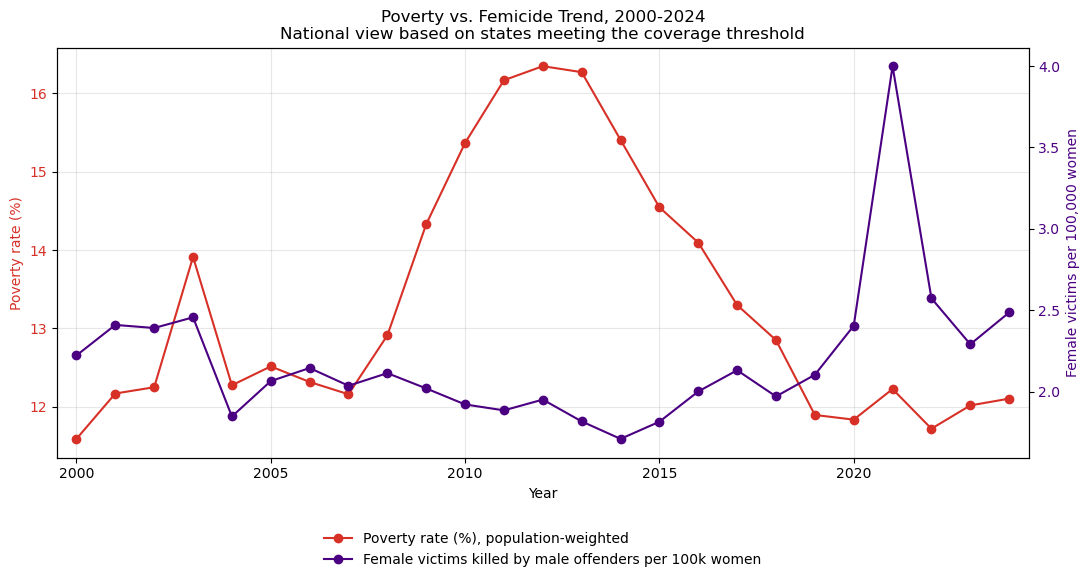

Saved: poverty_vs_femicide_trend_2000_2024.png


In [42]:
import pandas as pd
import matplotlib.pyplot as plt

DATA_FILE = "state_year_normalized.csv"
OUT_PNG = "poverty_vs_femicide_trend_2000_2024.png"
YEAR_MIN, YEAR_MAX = 2000, 2024

df = pd.read_csv(DATA_FILE, low_memory=False)
df["year"] = pd.to_numeric(df["year"], errors="coerce").astype(int)
df = df[df["year"].between(YEAR_MIN, YEAR_MAX)].copy()
df = df[df["reliable"].astype(str).str.lower().isin(["true", "1"])].copy()

df["pov_x_pop"] = df["poverty_rate"] * df["pop_total"]

yearly = df.groupby("year").agg(
    victims=("fem_victims", "sum"),
    fem_pop=("covered_female_pop", "sum"),
    pov_x_pop=("pov_x_pop", "sum"),
    pop=("pop_total", "sum"),
    states=("state_abb", "nunique"),
)
yearly["femicide_rate"] = yearly["victims"] / yearly["fem_pop"] * 100_000
yearly["poverty_rate"] = yearly["pov_x_pop"] / yearly["pop"]

print(yearly[["states", "poverty_rate", "femicide_rate"]].round(2).to_string())
print(f"\nYears: {YEAR_MIN}-{YEAR_MAX}, years plotted: {len(yearly)}")

fig, ax1 = plt.subplots(figsize=(11, 6))
ax1.plot(yearly.index, yearly["poverty_rate"], marker="o", color="#d73027",
         label="Poverty rate (%), population-weighted")
ax1.set_xlabel("Year")
ax1.set_ylabel("Poverty rate (%)", color="#d73027")
ax1.tick_params(axis="y", labelcolor="#d73027")
ax1.set_xlim(YEAR_MIN - 0.5, YEAR_MAX + 0.5)

ax2 = ax1.twinx()
ax2.plot(yearly.index, yearly["femicide_rate"], marker="o", color="#4B0082",
         label="Female victims killed by male offenders per 100k women")
ax2.set_ylabel("Female victims per 100,000 women", color="#4B0082")
ax2.tick_params(axis="y", labelcolor="#4B0082")

lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
labels = ax1.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax1.legend(lines, labels, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=1, frameon=False)

ax1.set_title(f"Poverty vs. Femicide Trend, {YEAR_MIN}-{YEAR_MAX}\n"
              "National view based on states meeting the coverage threshold")
ax1.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_PNG, dpi=150)
plt.show()
print("Saved:", OUT_PNG)